# Lambda jumps in spectral bandwidth selection

**Experiment 1:** draw 1,000 independent $N(0,1)$ samples of size $n=200$. For each sample, repeat the full Figure 3.3 lambda sweep and record the adjacent lambda pair containing its largest upward bandwidth-index change. Plot a histogram with one bin per lambda pair, and inspect the sizes of these changes separately.

Run the cells in order. Defaults reproduce Figure 3.3's numerical settings: 201 geometric bandwidths on $[0.01,2]$, 101 geometric lambda values on $[0.01,10^4]$, and the shared FFT divergence and stabilized Perron solver. Each sample stays fixed throughout its lambda sweep. The 1,000-sample results are checkpointed and reused when this notebook is rerun with the same settings.

The detector is an **operational finite-grid definition**, proposed for this experiment. A largest upward change can be small or tied; finding it does not establish a discontinuity or a statistically significant change point. The notebook records ties, samples with no upward change, and numerical failures explicitly.

Sources: [Figure 3.3 computation, cell `stationary-example-lambda-sensitivity`](spectral_scale_selection_kde.ipynb); [shared bandwidth grid](kde_tools/bandwidths.py); [FFT divergence implementation](kde_tools/fourier/similarities.py); [Perron solver and peak-selection convention](kde_tools/perron.py).

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import sys
import time
from pathlib import Path

working_directory = Path.cwd().resolve()
code_directory = next(
    (candidate.resolve()
     for root in (working_directory, *working_directory.parents)
     for candidate in (root, root / "Code" / "Code_kde")
     if (candidate / "kde_tools" / "pdf_export.py").is_file()),
    None,
)
if code_directory is None:
    raise FileNotFoundError("Run this notebook from MASTERARBEIT or Code/Code_kde.")
if str(code_directory) not in sys.path:
    sys.path.insert(0, str(code_directory))
os.environ.setdefault("MPLCONFIGDIR", str(code_directory / ".matplotlib-cache"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from threadpoolctl import threadpool_limits

from kde_tools.bandwidths import bandwidth_grid_linear_in_psi_beta
from kde_tools.fourier import beta2_divergence_matrix_fft
from kde_tools.pdf_export import enable_automatic_pdf_saving
from kde_tools.perron import (
    PERRON_SOLVER_VERSION,
    PerronConvergenceError,
    PerronDegeneracyError,
    perron_eigenpair_from_divergence,
)

notebook_name = "spectral_lambda_jump_study"
pdf_output_directory = enable_automatic_pdf_saving(
    notebook_name, output_root=code_directory / "outputs" / "pdfs"
)
data_root = code_directory / "outputs" / "data" / notebook_name
image_output_directory = code_directory / "outputs" / "images" / notebook_name
print(f"Automatic PDF exports: {pdf_output_directory}")
print(f"Perron solver: {PERRON_SOLVER_VERSION}")

Automatic PDF exports: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study
Perron solver: stabilized_lanczos_v1


## What counts as a jump in this experiment?

For repetition $r$, let $i_{r,k}$ be the zero-based selected bandwidth index at $\lambda_k$. Define

$$d_{r,k}=i_{r,k+1}-i_{r,k}, \qquad
k_r^*=\min\operatorname{arg\,max}_{0\leq k<100}d_{r,k}.$$

If $\max_k d_{r,k}>0$, record the pair $(\lambda_{k_r^*},\lambda_{k_r^*+1})$. Otherwise record **no upward change**. When several pairs share the largest positive change, the earliest pair is selected for the histogram; all tied pair indices and their count are saved in the results table. This is an explicit tie convention, not evidence that a single transition has been identified.

On the geometric bandwidth grid, my algebraic observation is that $d_{r,k}$ is proportional to $\log(h_{i_{r,k+1}}/h_{i_{r,k}})$. Thus this rule also selects the largest upward multiplicative bandwidth change. All lambda intervals have the same width in log space, so one histogram bin represents one adjacent pair. No interval midpoint is treated as an observed transition point.

The grid is `np.geomspace(1e-2, 1e4, 101)`, equivalently $\lambda_k=10^{-2+0.06k}$. NumPy specifies geometric spacing in its [geomspace documentation](https://numpy.org/doc/stable/reference/generated/numpy.geomspace.html); adjacent differences and first-maximum behavior are documented in [diff](https://numpy.org/doc/stable/reference/generated/numpy.diff.html) and [argmax](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html).

In [2]:
# Experiment 1: full run. Change M for a short preview.
M = 1000
SAMPLE_SIZE = 200
SEED = 20261013
NORMAL_MEAN = 0.0
NORMAL_STD = 1.0

N_BANDWIDTHS = 201
H_MIN, H_MAX = 0.01, 2.0
BANDWIDTH_GRID_BETA = 2.0  # Keep geometric spacing for the index-based detector.
LAMBDA_VALUES = np.geomspace(1e-2, 1e4, 101)
FFT_HALF_WIDTH = 12.0
FFT_SPATIAL_POINTS = 8192

CHECKPOINT_EVERY = 25
RETRY_NUMERICAL_FAILURES = False
CHECK_FIGURE_3_3 = True
# Presentation filter only: 1 includes every positive largest change.
# Increase this to inspect larger changes; it is an exploratory cutoff.
HISTOGRAM_MIN_STEPS = 1

if not isinstance(M, int) or M < 1 or SAMPLE_SIZE < 1:
    raise ValueError("M and SAMPLE_SIZE must be positive integers.")
if SEED < 0 or NORMAL_STD <= 0 or CHECKPOINT_EVERY < 1:
    raise ValueError("Require SEED >= 0, NORMAL_STD > 0, CHECKPOINT_EVERY >= 1.")
if BANDWIDTH_GRID_BETA != 2.0:
    raise ValueError("This experiment's index-based detector uses a geometric bandwidth grid.")
LAMBDA_VALUES = np.asarray(LAMBDA_VALUES, dtype=float)
if (LAMBDA_VALUES.ndim != 1 or len(LAMBDA_VALUES) < 3
        or not np.all(np.isfinite(LAMBDA_VALUES))
        or np.any(LAMBDA_VALUES <= 0) or np.any(np.diff(LAMBDA_VALUES) <= 0)):
    raise ValueError("Provide at least three finite, positive, increasing lambda values.")
if not np.allclose(np.diff(np.log(LAMBDA_VALUES)), np.diff(np.log(LAMBDA_VALUES))[0]):
    raise ValueError("Use a geometric lambda grid for this experiment.")

H_GRID = bandwidth_grid_linear_in_psi_beta(
    h_min=H_MIN, h_max=H_MAX, beta=BANDWIDTH_GRID_BETA, grid_size=N_BANDWIDTHS
)
print(f"M={M}, n={SAMPLE_SIZE}, bandwidth candidates={len(H_GRID)}, lambdas={len(LAMBDA_VALUES)}")
print(f"Adjacent lambda ratio: {LAMBDA_VALUES[1] / LAMBDA_VALUES[0]:.10f}")

M=1000, n=200, bandwidth candidates=201, lambdas=101
Adjacent lambda ratio: 1.1481536215


In [3]:
JUMP_RULE_VERSION = "largest_positive_index_step_first_tie_v1"


def largest_upward_jump(selected_indices, lambda_values, bandwidth_grid):
    """Summarize a complete path; do not invent a pair if no step is positive."""
    selected_indices = np.asarray(selected_indices, dtype=np.int64)
    lambda_values = np.asarray(lambda_values, dtype=float)
    bandwidth_grid = np.asarray(bandwidth_grid, dtype=float)
    if (selected_indices.ndim != 1 or selected_indices.shape != lambda_values.shape
            or len(selected_indices) < 3 or np.any(selected_indices < 0)
            or np.any(selected_indices >= len(bandwidth_grid))):
        raise ValueError("Require a complete, valid path on the supplied bandwidth grid.")
    steps = np.diff(selected_indices)
    largest_step = int(steps.max())
    if largest_step <= 0:
        return {
            "status": "no_upward_change", "pair_index": -1,
            "lambda_left": np.nan, "lambda_right": np.nan,
            "index_before": -1, "index_after": -1,
            "h_before": np.nan, "h_after": np.nan,
            "jump_steps": 0, "h_ratio": np.nan, "delta_h": np.nan,
            "runner_up_steps": 0, "n_tied_maxima": 0, "tied_pair_indices": "",
        }
    tied_pairs = np.flatnonzero(steps == largest_step)
    k = int(tied_pairs[0])
    before, after = int(selected_indices[k]), int(selected_indices[k + 1])
    h_before, h_after = float(bandwidth_grid[before]), float(bandwidth_grid[after])
    return {
        "status": "upward_change", "pair_index": k,
        "lambda_left": float(lambda_values[k]), "lambda_right": float(lambda_values[k + 1]),
        "index_before": before, "index_after": after,
        "h_before": h_before, "h_after": h_after,
        "jump_steps": largest_step, "h_ratio": h_after / h_before,
        "delta_h": h_after - h_before,
        "runner_up_steps": max(0, int(np.delete(steps, k).max())),
        "n_tied_maxima": len(tied_pairs),
        "tied_pair_indices": ";".join(map(str, tied_pairs.tolist())),
    }


def compute_selection_path(samples, bandwidth_grid, lambda_values,
                           half_width=12.0, spatial_points=8192):
    """Calculate D once per sample; reuse it for every lambda."""
    divergence = beta2_divergence_matrix_fft(
        samples=samples, h_grid=bandwidth_grid,
        half_width=half_width, spatial_points=spatial_points,
    )
    indices = np.empty(len(lambda_values), dtype=np.int32)
    residuals = np.empty(len(lambda_values))
    relative_gaps = np.empty(len(lambda_values))
    for k, lambda_value in enumerate(lambda_values):
        result = perron_eigenpair_from_divergence(divergence, float(lambda_value))
        indices[k] = result.selected_index
        residuals[k] = result.relative_residual
        relative_gaps[k] = result.relative_gap
    return indices, residuals, relative_gaps


# Detector checks: unique large change, tied maxima, no upward change,
# and unsigned input (the detector converts it before differencing).
_test_lambdas = np.geomspace(1, 100, 4)
_test_h = np.geomspace(0.01, 2, 10)
assert largest_upward_jump([1, 2, 7, 6], _test_lambdas, _test_h)["pair_index"] == 1
_tie = largest_upward_jump([1, 3, 3, 5], _test_lambdas, _test_h)
assert _tie["pair_index"] == 0 and _tie["n_tied_maxima"] == 2
assert _tie["tied_pair_indices"] == "0;2"
assert largest_upward_jump([3, 2, 2, 1], _test_lambdas, _test_h)["status"] == "no_upward_change"
assert largest_upward_jump(np.array([3, 2, 2, 1], dtype=np.uint16),
                           _test_lambdas, _test_h)["status"] == "no_upward_change"
print("Detector checks passed.")

Detector checks passed.


## Reproduce the Figure 3.3 reference

This check uses the figure's fixed seed 20260823 and its original settings independently of the Monte Carlo settings. It must recover lambda positions 54 and 55 (zero-based), bandwidth indices 91 and 114, and a 23-step increase. The reference comes from the [saved Figure 3.3 values](outputs/analysis/perron_figures_3_1_to_3_4/figure_3_3_comparison.csv). Set `CHECK_FIGURE_3_3=False` to skip this check in later exploratory runs.

In [4]:
if CHECK_FIGURE_3_3:
    reference_lambdas = np.geomspace(1e-2, 1e4, 101)
    reference_h_grid = bandwidth_grid_linear_in_psi_beta(grid_size=201)
    reference_samples = np.random.default_rng(20260823).normal(size=200)
    with threadpool_limits(limits=1):
        reference_indices, reference_residuals, reference_gaps = compute_selection_path(
            reference_samples, reference_h_grid, reference_lambdas
        )
    reference_jump = largest_upward_jump(reference_indices, reference_lambdas, reference_h_grid)
    assert reference_jump["pair_index"] == 54
    assert (reference_jump["index_before"], reference_jump["index_after"]) == (91, 114)
    assert reference_jump["jump_steps"] == 23
    print("Figure 3.3 reproduced:")
    print(json.dumps(reference_jump, indent=2))
    print(f"Maximum relative eigenpair residual: {reference_residuals.max():.3e}")
else:
    print("Figure 3.3 reference check skipped.")

Figure 3.3 reproduced:
{
  "status": "upward_change",
  "pair_index": 54,
  "lambda_left": 17.378008287493746,
  "lambda_right": 19.952623149688787,
  "index_before": 91,
  "index_after": 114,
  "h_before": 0.11142140949205241,
  "h_after": 0.2049212977328429,
  "jump_steps": 23,
  "h_ratio": 1.8391554968388706,
  "delta_h": 0.09349988824079049,
  "runner_up_steps": 2,
  "n_tied_maxima": 1,
  "tied_pair_indices": "54"
}
Maximum relative eigenpair residual: 9.812e-16


## Run or resume 1,000 independent samples

Repetition `r` uses `default_rng(SeedSequence([SEED, r]))`, so its sample is reproducible without depending on earlier repetitions or checkpoint boundaries. Raw samples, all 101 selected indices, and the residual/gap diagnostics are stored in a configuration-specific checkpoint. Numerical failures are recorded separately and excluded from the histogram; unfinished repetitions resume automatically. Enable `RETRY_NUMERICAL_FAILURES` to retry recorded solver failures.

Sources: [NumPy parallel random generation and SeedSequence](https://numpy.org/doc/stable/reference/random/parallel.html); [shared solver's residual and gap checks](kde_tools/perron.py). The sampling and checkpoint policy is a design choice for this notebook.

In [5]:
# Fingerprint settings and shared numerical source to avoid mixing configurations.
shared_source_files = [
    "kde_tools/perron.py", "kde_tools/bandwidths.py", "kde_tools/similarities.py",
    "kde_tools/fourier/similarities.py", "kde_tools/fourier/reconstruction.py",
]
configuration = {
    "M": M, "sample_size": SAMPLE_SIZE, "seed": SEED,
    "normal_mean": NORMAL_MEAN, "normal_std": NORMAL_STD,
    "sampling_rule": "default_rng_SeedSequence_seed_repetition_v1",
    "bandwidth_grid": H_GRID.tolist(), "lambda_values": LAMBDA_VALUES.tolist(),
    "fft_half_width": FFT_HALF_WIDTH, "fft_spatial_points": FFT_SPATIAL_POINTS,
    "perron_solver": PERRON_SOLVER_VERSION, "jump_rule": JUMP_RULE_VERSION,
    "numpy_version": np.__version__, "scipy_version": scipy.__version__,
    "shared_source_sha256": {
        name: hashlib.sha256((code_directory / name).read_bytes()).hexdigest()
        for name in shared_source_files
    },
}
configuration_json = json.dumps(configuration, sort_keys=True)
configuration_id = hashlib.sha256(configuration_json.encode()).hexdigest()[:12]
run_directory = data_root / configuration_id
run_directory.mkdir(parents=True, exist_ok=True)
run_image_directory = image_output_directory / configuration_id
run_image_directory.mkdir(parents=True, exist_ok=True)
checkpoint_path = run_directory / "checkpoint.npz"
(run_directory / "configuration.json").write_text(
    json.dumps(configuration, indent=2) + "\n", encoding="utf-8"
)

samples = np.vstack([
    np.random.default_rng(np.random.SeedSequence([SEED, r])).normal(
        loc=NORMAL_MEAN, scale=NORMAL_STD, size=SAMPLE_SIZE
    )
    for r in range(M)
])
selected_indices = np.full((M, len(LAMBDA_VALUES)), -1, dtype=np.int32)
relative_residuals = np.full(selected_indices.shape, np.nan)
relative_gaps = np.full(selected_indices.shape, np.nan)
finished = np.zeros(M, dtype=bool)
numerical_success = np.zeros(M, dtype=bool)
error_messages = np.full(M, "", dtype="<U1000")
if checkpoint_path.is_file():
    with np.load(checkpoint_path, allow_pickle=False) as cached:
        if str(cached["configuration_json"].item()) != configuration_json:
            raise ValueError("Checkpoint configuration mismatch.")
        if not np.array_equal(cached["samples"], samples):
            raise ValueError("Checkpoint samples do not match this sampling configuration.")
        for name in ["selected_indices", "relative_residuals", "relative_gaps",
                     "finished", "numerical_success", "error_messages"]:
            if cached[name].shape != globals()[name].shape:
                raise ValueError(f"Checkpoint shape mismatch for {name}.")
            globals()[name] = cached[name].copy()
    print(f"Loaded {finished.sum()}/{M} finished repetitions from {checkpoint_path}")
if RETRY_NUMERICAL_FAILURES:
    finished[finished & ~numerical_success] = False


def save_checkpoint():
    temporary_path = checkpoint_path.with_suffix(".npz.tmp")
    with temporary_path.open("wb") as stream:
        np.savez_compressed(
            stream, configuration_json=configuration_json, samples=samples,
            lambda_values=LAMBDA_VALUES, bandwidth_grid=H_GRID,
            selected_indices=selected_indices, relative_residuals=relative_residuals,
            relative_gaps=relative_gaps, finished=finished,
            numerical_success=numerical_success, error_messages=error_messages,
        )
    temporary_path.replace(checkpoint_path)


pending_repetitions = np.flatnonzero(~finished)
started = time.perf_counter()
print(f"Configuration {configuration_id}: {len(pending_repetitions)} repetitions to calculate.")
try:
    # Prevent a small matrix solve from launching excessive BLAS threads.
    with threadpool_limits(limits=1):
        for completed_this_run, r in enumerate(pending_repetitions, start=1):
            r = int(r)
            try:
                path, residuals, gaps = compute_selection_path(
                    samples[r], H_GRID, LAMBDA_VALUES,
                    half_width=FFT_HALF_WIDTH, spatial_points=FFT_SPATIAL_POINTS,
                )
            except (PerronConvergenceError, PerronDegeneracyError) as error:
                numerical_success[r] = False
                error_messages[r] = f"{type(error).__name__}: {error}"
                print(f"Recorded numerical failure at repetition {r}: {error}")
            else:
                selected_indices[r] = path
                relative_residuals[r] = residuals
                relative_gaps[r] = gaps
                numerical_success[r] = True
                error_messages[r] = ""
            finished[r] = True
            if completed_this_run % CHECKPOINT_EVERY == 0:
                save_checkpoint()
                elapsed = time.perf_counter() - started
                remaining = len(pending_repetitions) - completed_this_run
                eta = elapsed / completed_this_run * remaining
                print(f"Finished {finished.sum()}/{M}; elapsed {elapsed:.1f}s; remaining about {eta:.1f}s", flush=True)
finally:
    save_checkpoint()

print(f"Finished {finished.sum()}/{M}; numerically successful: {numerical_success.sum()}; failures: {(finished & ~numerical_success).sum()}")
print(f"Saved raw samples and trajectories: {checkpoint_path}")

Loaded 1000/1000 finished repetitions from /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_jump_study/2ce04db2a16e/checkpoint.npz
Configuration 2ce04db2a16e: 0 repetitions to calculate.
Finished 1000/1000; numerically successful: 1000; failures: 0
Saved raw samples and trajectories: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_jump_study/2ce04db2a16e/checkpoint.npz


In [6]:
if not np.all(finished):
    raise RuntimeError("Resume the sampling cell before summarizing an incomplete experiment.")
records = []
for r in range(M):
    record = {"repetition": r, "sampling_seed": SEED}
    if numerical_success[r]:
        record.update(largest_upward_jump(selected_indices[r], LAMBDA_VALUES, H_GRID))
        record["max_relative_residual"] = float(relative_residuals[r].max())
        record["min_relative_gap"] = float(relative_gaps[r].min())
        record["error"] = ""
    else:
        record.update({"status": "numerical_failure", "pair_index": -1,
                       "jump_steps": np.nan, "error": error_messages[r]})
    records.append(record)
results = pd.DataFrame(records)
results.to_csv(run_directory / "jump_results.csv", index=False)

if not numerical_success.any():
    raise RuntimeError("All samples failed numerically. Inspect jump_results.csv before plotting.")
upward = results.loc[results["status"] == "upward_change"].copy()
counts = np.bincount(upward["pair_index"].to_numpy(dtype=int),
                     minlength=len(LAMBDA_VALUES) - 1)
unique_counts = np.bincount(
    upward.loc[upward["n_tied_maxima"] == 1, "pair_index"].to_numpy(dtype=int),
    minlength=len(LAMBDA_VALUES) - 1,
)
tied_counts = counts - unique_counts
pair_histogram = pd.DataFrame({
    "pair_index": np.arange(len(LAMBDA_VALUES) - 1),
    "lambda_left": LAMBDA_VALUES[:-1], "lambda_right": LAMBDA_VALUES[1:],
    "count": counts, "unique_maximum_count": unique_counts, "tied_maximum_count": tied_counts,
    "fraction_of_all_samples": counts / M,
    "fraction_of_upward_change_samples": counts / max(1, len(upward)),
})
pair_histogram.to_csv(run_directory / "lambda_pair_histogram.csv", index=False)
assert int(counts.sum()) == len(upward)
summary = {
    "configuration_id": configuration_id, "samples": M,
    "numerical_successes": int(numerical_success.sum()),
    "numerical_failures": int((~numerical_success).sum()),
    "samples_with_upward_change": len(upward),
    "samples_with_no_upward_change": int((results["status"] == "no_upward_change").sum()),
    "samples_with_tied_largest_changes": int((upward["n_tied_maxima"] > 1).sum()),
    "samples_with_largest_change_at_most_2_steps": int((upward["jump_steps"] <= 2).sum()),
    "samples_with_largest_change_at_least_5_steps": int((upward["jump_steps"] >= 5).sum()),
    "median_largest_upward_steps": float(upward["jump_steps"].median()) if len(upward) else None,
    "largest_relative_eigenpair_residual": float(np.nanmax(relative_residuals)) if numerical_success.any() else None,
}
(run_directory / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print(json.dumps(summary, indent=2))
print("\nMost frequent lambda pairs (earliest pair chosen in ties):")
print(pair_histogram.sort_values("count", ascending=False).head(10).to_string(index=False))

{
  "configuration_id": "2ce04db2a16e",
  "samples": 1000,
  "numerical_successes": 1000,
  "numerical_failures": 0,
  "samples_with_upward_change": 973,
  "samples_with_no_upward_change": 27,
  "samples_with_tied_largest_changes": 508,
  "samples_with_largest_change_at_most_2_steps": 483,
  "samples_with_largest_change_at_least_5_steps": 344,
  "median_largest_upward_steps": 3.0,
  "largest_relative_eigenpair_residual": 1.6975870221346365e-15
}

Most frequent lambda pairs (earliest pair chosen in ties):
 pair_index  lambda_left  lambda_right  count  unique_maximum_count  tied_maximum_count  fraction_of_all_samples  fraction_of_upward_change_samples
         57    26.302680     30.199517     46                    26                  20                    0.046                           0.047276
         58    30.199517     34.673685     42                    19                  23                    0.042                           0.043165
         70   158.489319    181.970086     40 

## Histogram of adjacent lambda pairs

Each bar counts samples whose largest positive index change occurred between that bin's two lambda endpoints. The horizontal axis is logarithmic; bar height is a sample count, not a probability density per unit lambda. The default `HISTOGRAM_MIN_STEPS=1` includes all positive largest changes. Raise it and rerun only the plot cell to inspect larger changes; the CSV histogram retains the unfiltered counts.

The orange interval marks the fixed sample's Figure 3.3 pair, approximately $(17.3780,19.9526)$. The darker bars count unique largest changes; the lighter portions count tied maxima allocated to their earliest pair. Their stacked heights give the requested total counts. Ties are also reported in the annotation. A secondary histogram shows change sizes, including zero for numerically successful samples with no upward change.

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study/001_largest_upward_change_lambda_pair_histogram_m_1000_n_200_n_201.pdf


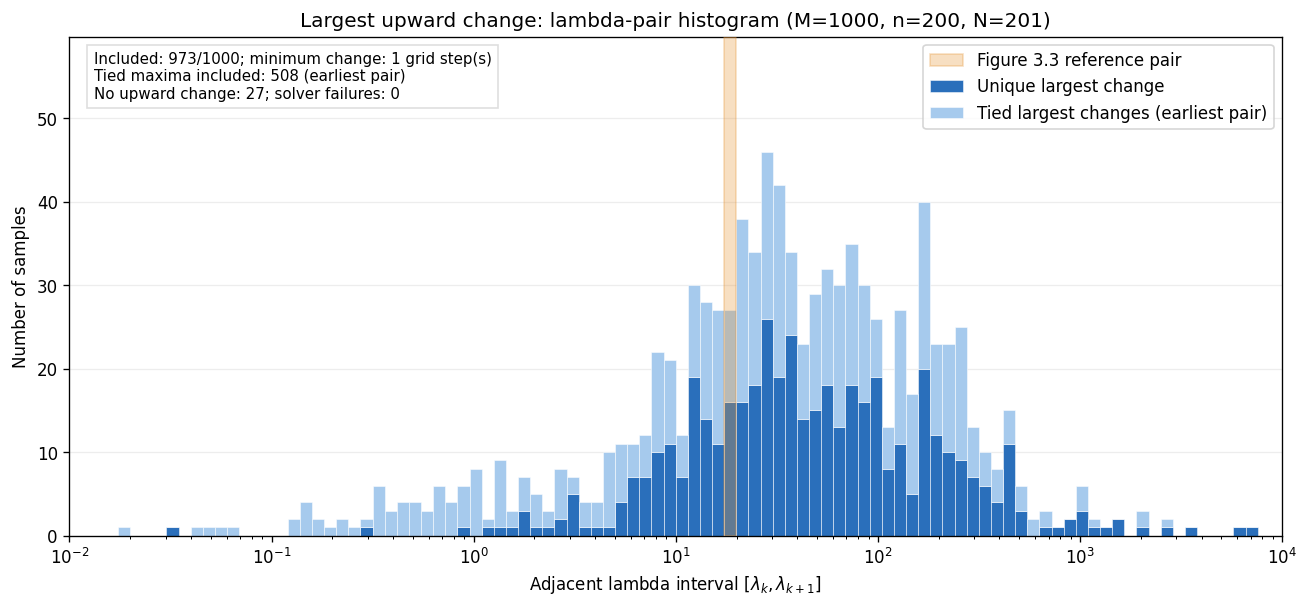

In [7]:
if not isinstance(HISTOGRAM_MIN_STEPS, int) or HISTOGRAM_MIN_STEPS < 1:
    raise ValueError("HISTOGRAM_MIN_STEPS must be a positive integer.")
plotted = upward.loc[upward["jump_steps"] >= HISTOGRAM_MIN_STEPS]
plot_counts = np.bincount(plotted["pair_index"].to_numpy(dtype=int),
                          minlength=len(LAMBDA_VALUES) - 1)
plot_unique_counts = np.bincount(
    plotted.loc[plotted["n_tied_maxima"] == 1, "pair_index"].to_numpy(dtype=int),
    minlength=len(LAMBDA_VALUES) - 1,
)
plot_tied_counts = plot_counts - plot_unique_counts
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.bar(LAMBDA_VALUES[:-1], plot_unique_counts, width=np.diff(LAMBDA_VALUES),
       align="edge", color="#2a6fbb", edgecolor="white", linewidth=0.3,
       label="Unique largest change", zorder=2)
ax.bar(LAMBDA_VALUES[:-1], plot_tied_counts, width=np.diff(LAMBDA_VALUES),
       bottom=plot_unique_counts, align="edge", color="#a6caed", edgecolor="white",
       linewidth=0.3, label="Tied largest changes (earliest pair)", zorder=2)
ax.axvspan(17.378008287493746, 19.952623149688787, color="#e69536",
           alpha=0.3, label="Figure 3.3 reference pair", zorder=3)
ax.set_xscale("log")
ax.set_xlim(LAMBDA_VALUES[0], LAMBDA_VALUES[-1])
ax.set_ylim(0, max(1, int(plot_counts.max())) * 1.3)
ax.set_xlabel(r"Adjacent lambda interval $[\lambda_k,\lambda_{k+1}]$")
ax.set_ylabel("Number of samples")
ax.set_title(f"Largest upward change: lambda-pair histogram (M={M}, n={SAMPLE_SIZE}, N={len(H_GRID)})")
annotation = (
    f"Included: {len(plotted)}/{M}; minimum change: {HISTOGRAM_MIN_STEPS} grid step(s)\n"
    f"Tied maxima included: {int((plotted['n_tied_maxima'] > 1).sum())} (earliest pair)\n"
    f"No upward change: {summary['samples_with_no_upward_change']}; solver failures: {summary['numerical_failures']}"
)
ax.text(0.02, 0.97, annotation, transform=ax.transAxes, va="top", fontsize=9,
        bbox={"facecolor": "white", "edgecolor": "#dddddd", "alpha": 0.95})
ax.grid(axis="y", alpha=0.22, zorder=0)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(run_image_directory / f"lambda_pair_histogram_min_steps_{HISTOGRAM_MIN_STEPS}.png",
            dpi=150, bbox_inches="tight")
plt.show()  # Shared exporter automatically saves this figure as PDF.
plt.close(fig)

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_jump_study/002_sizes_of_the_largest_upward_changes_1000_successful_samples.pdf


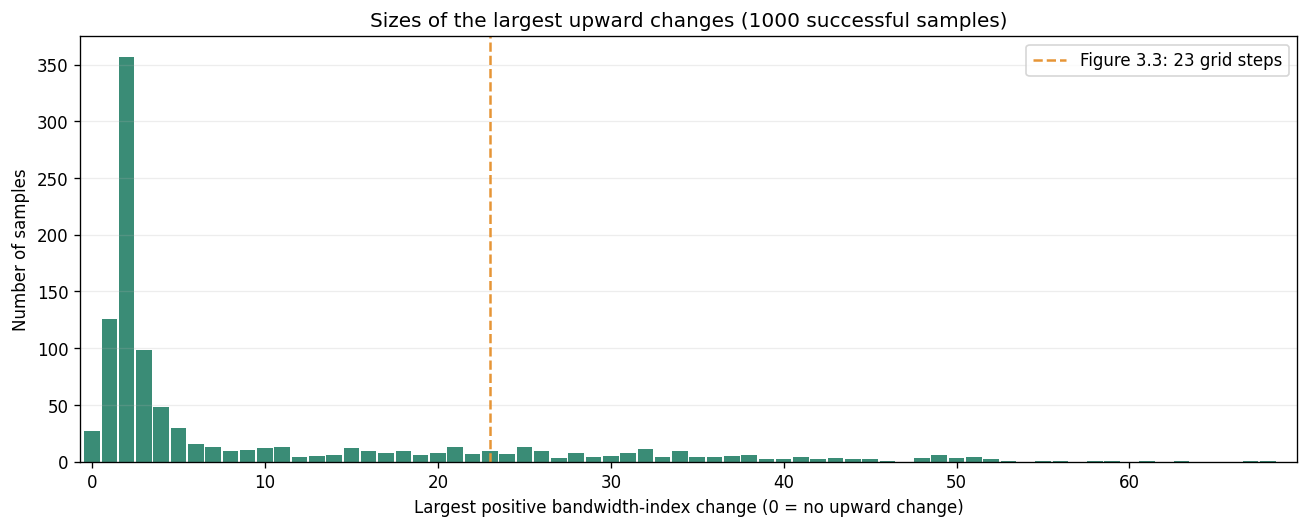

In [8]:
successful_results = results.loc[results["status"] != "numerical_failure"]
sizes = successful_results["jump_steps"].to_numpy(dtype=int)
size_counts = np.bincount(sizes, minlength=1)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(np.arange(len(size_counts)), size_counts, color="#3a8c76", width=0.9)
ax.axvline(23, color="#e69536", linestyle="--", label="Figure 3.3: 23 grid steps")
ax.set_xlim(-0.7, max(24, len(size_counts)) + 0.7)
ax.set_ylim(bottom=0)
ax.set_xlabel("Largest positive bandwidth-index change (0 = no upward change)")
ax.set_ylabel("Number of samples")
ax.set_title(f"Sizes of the largest upward changes ({len(successful_results)} successful samples)")
ax.grid(axis="y", alpha=0.22)
ax.legend()
fig.tight_layout()
fig.savefig(run_image_directory / "largest_upward_change_sizes.png", dpi=150, bbox_inches="tight")
plt.show()  # Shared exporter automatically saves this figure as PDF.
plt.close(fig)

## Interpretation and next experiments

Read the lambda-pair histogram together with the size histogram and the tie count. Repeated small steps can produce many equally large changes; allocating those to the earliest pair is a reproducible convention with a possible effect on the first histogram. The columns `n_tied_maxima`, `tied_pair_indices`, `jump_steps`, and `runner_up_steps` make this visible. The histogram is descriptive of this detector, distribution, sample size, bandwidth grid, and lambda grid.

The checkpoint preserves each sample and its complete selection path. Later experiments can refine lambda values inside the recorded brackets, compare competing Perron peaks, check sensitivity to grid resolution, or change the data distribution. A coarse-grid maximum alone does not verify a discontinuity; that remains a question for refinement and peak analysis.

Outputs for this configuration are `jump_results.csv`, `lambda_pair_histogram.csv`, `summary.json`, `configuration.json`, and `checkpoint.npz` in the printed data directory. The checkpoint contains `samples`, `selected_indices`, `relative_residuals`, `relative_gaps`, `lambda_values`, and `bandwidth_grid`. PNG previews are configuration-specific; every displayed figure also receives an automatic PDF under `outputs/pdfs/spectral_lambda_jump_study/`.

Implementation references: [original Figure 3.3 notebook](spectral_scale_selection_kde.ipynb); [shared FFT divergence](kde_tools/fourier/similarities.py); [shared solver](kde_tools/perron.py); [SciPy symmetric eigensolver documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.eigsh.html). The jump rule, tie policy across lambda pairs, and exploratory filtering are original choices for this study.